# 01 · Anatomía de una señal

**Objetivo:** seguir una fila de gwsim paso a paso:

1. la forma de onda h₊, h×;
2. la proyección en cada detector;
3. la SNR y el reescalado de la distancia;
4. el clic y la señal sin clic;
5. el blanqueado y el z-score;
6. las cuatro salidas `signal_projected`, `strain_noisy_raw`, `signal_whitened` y `X`.

Es la versión práctica de `docs/FISICA.md`; tenlo a mano.

**Requisitos:** haber hecho el tutorial 00. Paquete de PSD recomendable (si no, ruido analítico).

**Tiempo aproximado:** 1–2 minutos en CPU (2 filas completas).

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
if ROOT.name == 'tutorials':
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

PSD_PACK = 'psd_pack_o3b.npz'
pack_path = Path(PSD_PACK) if Path(PSD_PACK).is_absolute() else ROOT / PSD_PACK
USE_PACK = pack_path.is_file()
if not USE_PACK:
    warnings.warn(f'No encuentro {pack_path}: uso ruido analítico (curvas de diseño), no las PSD de O3b.')

from gwsim.noise import PsdPackNoise, AnalyticNoise
O3B_GPS = [1256655618.0, 1269363618.0]
noise = PsdPackNoise(pack_path, ['train']) if USE_PACK else AnalyticNoise(O3B_GPS)
COLORS = {'H1': '#d55e00', 'L1': '#0072b2', 'V1': '#009e73'}
IFOS = ['H1', 'L1', 'V1']

from gwsim.recipe import Physics, RowOptions, simulate_row, td_waveform_kwargs, band_for
from gwsim.physics.parameters import CBCParameters
phys = Physics()
cfg = phys.config

# La fuente que vamos a seguir: un sistema parecido a GW150914.
PARAMS = dict(mass_1=36.0, mass_2=29.0, spin_1z=0.3, spin_2z=-0.2,
              inclination=0.4, ra=1.2, dec=-0.3, polarization_angle=0.5)
assignment = noise.assign(1, np.random.default_rng(11))
GPS = float(assignment['gps'][0])
PSDS = noise.psds(assignment['block_id'][0], cfg)
print('GPS del centro de la ventana:', GPS, '| bloque de ruido:', assignment['block_id'][0])

/tmp/ipykernel_309199/847253481.py:15: UserWarning: No encuentro /afs/ciemat.es/user/v/vserrano/Desktop/gw/gwsim/psd_pack_o3b.npz: uso ruido analítico (curvas de diseño), no las PSD de O3b.
  warnings.warn(f'No encuentro {pack_path}: uso ruido analítico (curvas de diseño), no las PSD de O3b.')
/afs/ciemat.es/user/v/vserrano/miniconda3/envs/gw-env/lib/python3.10/site-packages/pycbc/types/array.py:36: UserWarning: Wswiglal-redir-stdio:

SWIGLAL standard output/error redirection is enabled in IPython.
This may lead to performance penalties. To disable locally, use:

with lal.no_swig_redirect_standard_output_error():
    ...

To disable globally, use:

lal.swig_redirect_standard_output_error(False)

Note however that this will likely lead to error messages from
LAL functions being either misdirected or lost when called from
Jupyter notebooks.

To suppress this warning, use:

import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")
import lal

  import lal as _lal
/afs/ciem

GPS del centro de la ventana: 1258289488.136791 | bloque de ruido: analytic


## 1. La forma de onda: h₊ y h×

Una binaria emite dos polarizaciones, h₊(t) y h×(t). SEOBNRv4_opt las calcula integrando las ecuaciones de un modelo *effective-one-body* calibrado con relatividad numérica, e incluye la espiral, la fusión y el *ringdown*.

gwsim las genera primero a una distancia de referencia de 1000 Mpc, desde f_lower = 30 Hz. El tiempo t = 0 corresponde al pico de la amplitud, aproximadamente la fusión. Fíjate en cómo crecen la frecuencia y la amplitud hacia la fusión: es el *chirp*.

Duración desde 30 Hz: 0.36 s (1480 muestras)


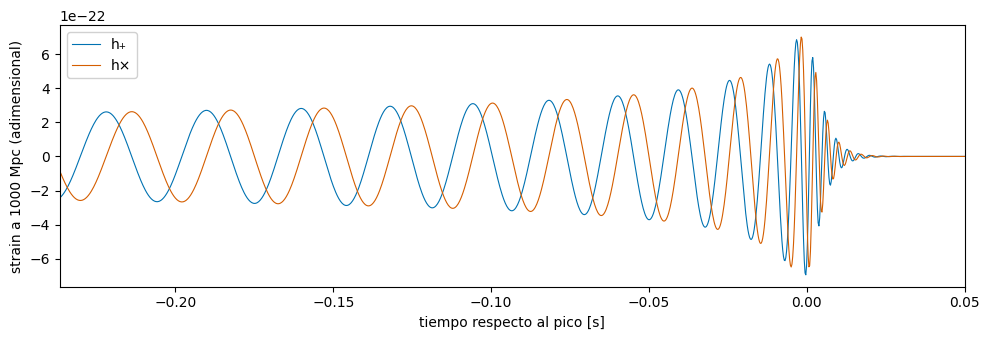

In [2]:
p_ref = CBCParameters(distance=1000.0, **PARAMS)
wf = phys.waveform_generator.generate(p_ref)
t_wf = wf.h_plus.sample_times.numpy()
print(f'Duración desde 30 Hz: {wf.metadata.duration:.2f} s ({wf.metadata.n_samples} muestras)')

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(t_wf, wf.h_plus.numpy(), color='#0072b2', lw=0.8, label='h₊')
ax.plot(t_wf, wf.h_cross.numpy(), color='#d55e00', lw=0.8, label='h×')
ax.set_xlim(t_wf[0], 0.05)
ax.set_xlabel('tiempo respecto al pico [s]')
ax.set_ylabel('strain a 1000 Mpc (adimensional)')
ax.legend(loc='upper left', framealpha=0.9)
plt.tight_layout()
plt.show()

## 2. Proyección en cada detector

Un interferómetro no mide h₊ y h× por separado, sino la combinación

h(t) = F₊(α, δ, ψ, t) · h₊(t) + F×(α, δ, ψ, t) · h×(t),

donde F₊ y F× son los **patrones de antena**. Dependen de la posición en el cielo (α, δ), del ángulo de polarización ψ y de la orientación del detector en ese instante (la Tierra gira, por eso dependen del GPS). Además, la onda llega a cada detector con un **retraso** respecto al centro de la Tierra: como mucho unos 21 ms, el tiempo de luz entre los detectores más alejados.

gwsim usa `Detector.project_wave` de PyCBC, que aplica las dos cosas.

H1: F+ = +0.471  Fx = +0.150  retraso respecto al geocentro = -1.64 ms
L1: F+ = -0.193  Fx = -0.475  retraso respecto al geocentro = +3.95 ms
V1: F+ = -0.124  Fx = +0.874  retraso respecto al geocentro = +18.63 ms


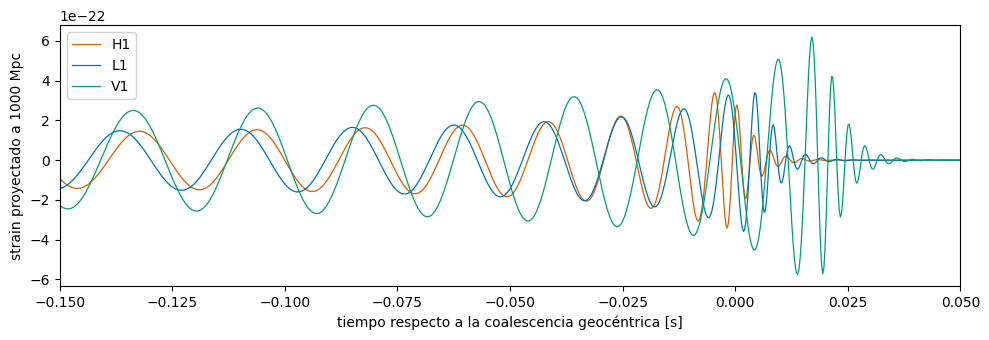

In [3]:
from pycbc.detector import Detector
proj = phys.projector.project(h_plus=wf.h_plus, h_cross=wf.h_cross, parameters=p_ref,
                              geocentric_coalescence_time=GPS)
for ifo in IFOS:
    fp, fc = Detector(ifo).antenna_pattern(p_ref.ra, p_ref.dec, p_ref.polarization_angle, GPS)
    delay = proj.metadata.expected_detector_time_delays[ifo]
    print(f'{ifo}: F+ = {fp:+.3f}  Fx = {fc:+.3f}  retraso respecto al geocentro = {1e3 * delay:+.2f} ms')

fig, ax = plt.subplots(figsize=(10, 3.5))
for ifo in IFOS:
    s = proj.strains[ifo]
    ax.plot(s.sample_times.numpy() - GPS, s.numpy(), color=COLORS[ifo], lw=0.9, label=ifo)
ax.set_xlim(-0.15, 0.05)
ax.set_xlabel('tiempo respecto a la coalescencia geocéntrica [s]')
ax.set_ylabel('strain proyectado a 1000 Mpc')
ax.legend(loc='upper left', framealpha=0.9)
plt.tight_layout()
plt.show()

Las tres curvas tienen amplitudes distintas (patrones de antena distintos) y están ligeramente desplazadas en el tiempo (retrasos). Esa información es la que permite localizar la fuente en el cielo.

## 3. Una fila completa con `simulate_row`

Ahora pedimos a gwsim la fila entera, con todas las salidas intermedias. La SNR objetivo es 15.

In [4]:
ALL = ('X', 'X_unnormalized', 'X_noise', 'signal_projected', 'signal_whitened', 'strain_noisy_raw')
out, meta = simulate_row(PARAMS, GPS, PSDS, placement_seed=7, gaussian_seed=8, target_snr=15.0,
                         opts=RowOptions(physics=phys, mode='snr', outputs=ALL))
for k in ('reference_network_snr', 'final_network_snr', 'snr_H1', 'snr_L1', 'snr_V1', 'final_distance',
          'placement_offset_s', 'band_f_lower', 'band_taper_end_hz', 'align_residual_rad'):
    print(f'{k:<24} {meta[k]:.6g}')
t = np.arange(cfg.length) / cfg.sampling_frequency
t_c = meta['actual_geocentric_time'] - (GPS - 0.5 * cfg.duration)   # coalescencia dentro de la ventana [s]

reference_network_snr    35.6481
final_network_snr        15
snr_H1                   7.33249
snr_L1                   7.56763
snr_V1                   10.6755
final_distance           2376.54
placement_offset_s       -0.403165
band_f_lower             15
band_taper_end_hz        25
align_residual_rad       1.56229e-18


### La SNR óptima

La SNR óptima de un detector, con S_n(f) la PSD unilateral del ruido, es

ρ² = 4 Re ∫ |h̃(f)|² / S_n(f) df, integrada de 30 a 1024 Hz.

Es la SNR media que daría un filtro adaptado perfecto. Pesa cada frecuencia por lo silencioso que es el detector en ella. La de la red es la suma en cuadratura de las tres: ρ_red = √(ρ_H1² + ρ_L1² + ρ_V1²).

La calculamos a mano, como una suma discreta sobre la FFT de `signal_projected`, y la comparamos con la que guarda gwsim, que usa `pycbc.filter.sigma`. Las dos no coinciden exactamente, por tres pequeñas diferencias:

- `signal_projected` está en float32;
- es la señal S sin clic, mientras que gwsim guarda la SNR de A (la sección 4 explica la diferencia);
- los bordes de la banda se redondean de forma distinta.

Aun así deben coincidir en unas milésimas.

In [5]:
from pycbc.types import TimeSeries
rho2_net = 0.0
for j, ifo in enumerate(IFOS):
    hf = TimeSeries(out['signal_projected'][j].astype(np.float64), delta_t=cfg.delta_t).to_frequencyseries()
    f = hf.sample_frequencies.numpy()
    band = (f >= 30.0) & (f < 1024.0)
    psd = PSDS['snr'][ifo].numpy()
    rho2 = 4.0 * np.sum(np.abs(hf.numpy()[band]) ** 2 / psd[band]) * hf.delta_f
    rho2_net += rho2
    print(f'{ifo}: a mano {np.sqrt(rho2):7.4f}   gwsim {meta["snr_" + ifo]:7.4f}')
print(f'red: a mano {np.sqrt(rho2_net):7.4f}   gwsim {meta["final_network_snr"]:7.4f}')

H1: a mano  7.3232   gwsim  7.3325
L1: a mano  7.5799   gwsim  7.5676
V1: a mano 10.6782   gwsim 10.6755
red: a mano 15.0036   gwsim 15.0000


### El reescalado de la distancia

La amplitud de la onda va como 1/d, así que la SNR también: ρ(d) = ρ_ref · d_ref / d. gwsim mide ρ_ref a d_ref = 1000 Mpc y elige

d = d_ref · ρ_ref / ρ_obj.

Después regenera la señal a esa distancia y comprueba que la SNR cae dentro del 5 % del objetivo. Si no, la fila falla.

In [6]:
d_formula = 1000.0 * meta['reference_network_snr'] / 15.0
print(f'1000 Mpc × {meta["reference_network_snr"]:.4f} / 15 = {d_formula:.3f} Mpc')
print(f'distancia final guardada por gwsim  = {meta["final_distance"]:.3f} Mpc')
print(f'SNR final {meta["final_network_snr"]:.4f}: error relativo {abs(meta["final_network_snr"] / 15 - 1):.2e} (tolerancia 5e-2)')

1000 Mpc × 35.6481 / 15 = 2376.541 Mpc
distancia final guardada por gwsim  = 2376.541 Mpc
SNR final 15.0000: error relativo 2.22e-16 (tolerancia 5e-2)


## 4. El clic y la señal sin clic

La forma de onda **A**, generada desde 30 Hz, empieza de golpe: su primera muestra no es cero. Un escalón así tiene potencia en todas las frecuencias (su transformada de Fourier decae solo como 1/f). Tras el blanqueado se convierte en un **clic**: un pulso breve que no tiene nada que ver con la física de la fuente, pero que un clasificador podría aprender a reconocer.

La solución de gwsim es la señal **S**, el mismo modelo, con dos cambios:

- empieza a una frecuencia más baja: **15 Hz** (banda de arranque baja) o, si M_tot > 180 M☉, **10 Hz** (banda alta);
- tiene una subida suave (media ventana de Kaiser) hasta que su frecuencia alcanza 25 Hz (14 Hz en la banda alta).

Así, el arranque queda por debajo de 30 Hz, donde el procesado elimina todo, y en la banda útil S coincide con A. S se alinea con A en fase y tiempo; `align_residual_rad` mide lo bien que lo consigue.

Comparamos h₊ de A y de S al principio de A:

A empieza en t = -0.237 s (30 Hz); S empieza en t = -1.715 s (15 Hz)
|primera muestra de A| / máx|A| = 0.350  <- el escalón


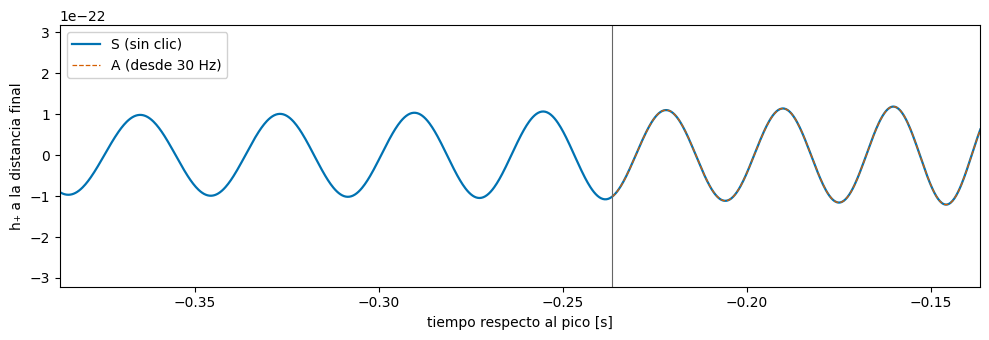

In [7]:
from pycbc.waveform import get_td_waveform
from gwsim.physics.clickfree import opt_click_free_aligned
p_fin = CBCParameters(distance=meta['final_distance'], **PARAMS)
opt_args = td_waveform_kwargs(cfg, p_fin)
hpA, hcA = get_td_waveform(**opt_args)
hpS, hcS, align = opt_click_free_aligned(opt_args, *band_for(p_fin.total_mass))
tA0 = float(hpA.start_time)
print(f'A empieza en t = {tA0:.3f} s (30 Hz); S empieza en t = {float(hpS.start_time):.3f} s ({band_for(p_fin.total_mass)[0]:g} Hz)')
print(f'|primera muestra de A| / máx|A| = {abs(hpA[0]) / np.abs(hpA.numpy()).max():.3f}  <- el escalón')

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(hpS.sample_times.numpy(), hpS.numpy(), color='#0072b2', lw=1.6, label='S (sin clic)')
ax.plot(hpA.sample_times.numpy(), hpA.numpy(), color='#d55e00', lw=0.9, ls='--', label='A (desde 30 Hz)')
ax.axvline(tA0, color='0.4', lw=0.8)
ax.set_xlim(tA0 - 0.15, tA0 + 0.1)
ax.set_xlabel('tiempo respecto al pico [s]')
ax.set_ylabel('h₊ a la distancia final')
ax.legend(loc='upper left', framealpha=0.9)
plt.tight_layout()
plt.show()

A la derecha de la línea gris, S y A son prácticamente la misma curva; a la izquierda, A no existe y S sigue, cada vez más suave. Veamos el efecto **después del blanqueado**. Repetimos la fila con `click_free=False`, que inyecta A. Las semillas son las mismas, así que la colocación y el ruido no cambian.

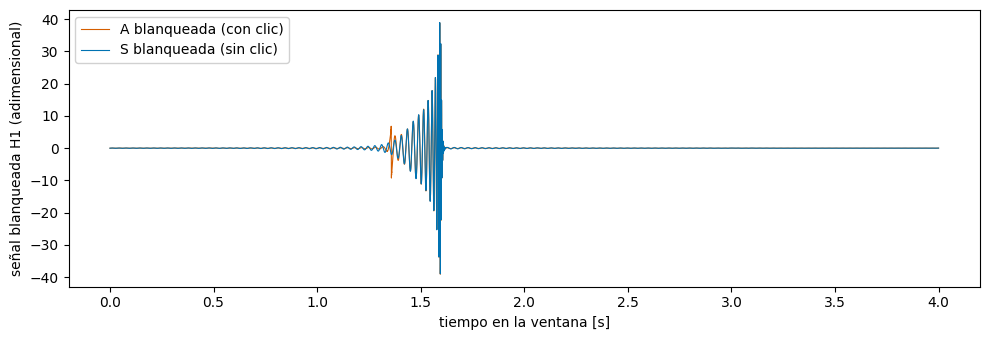

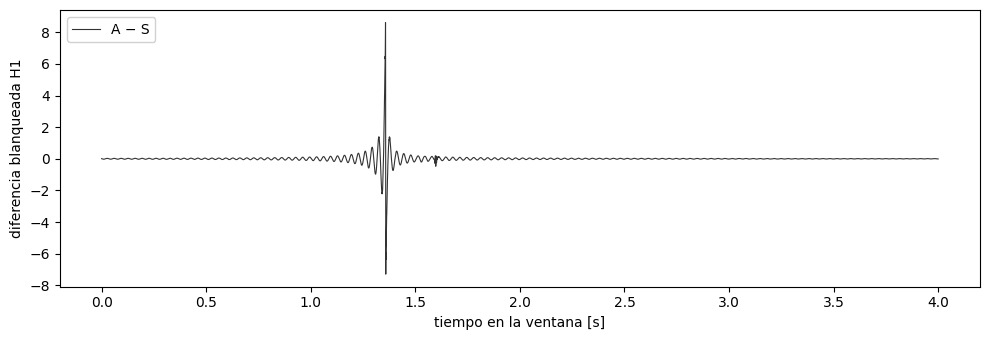

La distancia es la misma en las dos (sale de la SNR de A): True


In [8]:
out_A, meta_A = simulate_row(PARAMS, GPS, PSDS, placement_seed=7, gaussian_seed=8, target_snr=15.0,
                             opts=RowOptions(physics=phys, outputs=('signal_whitened',), click_free=False))
wS, wA = out['signal_whitened'][0], out_A['signal_whitened'][0]   # H1

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(t, wA, color='#d55e00', lw=0.8, label='A blanqueada (con clic)')
ax.plot(t, wS, color='#0072b2', lw=0.8, label='S blanqueada (sin clic)')
ax.set_xlabel('tiempo en la ventana [s]')
ax.set_ylabel('señal blanqueada H1 (adimensional)')
ax.legend(loc='upper left', framealpha=0.9)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(t, wA - wS, color='0.2', lw=0.8, label='A − S')
ax.set_xlabel('tiempo en la ventana [s]')
ax.set_ylabel('diferencia blanqueada H1')
ax.legend(loc='upper left', framealpha=0.9)
plt.tight_layout()
plt.show()
print('La distancia es la misma en las dos (sale de la SNR de A):', meta['final_distance'] == meta_A['final_distance'])

La diferencia A − S se concentra en un pulso alrededor del instante en que empieza A: ese es el clic. Si la señal es más larga que la ventana de 4 s, el inicio de A cae fuera de la ventana final y el clic no se ve, pero sigue estando en el segmento de procesado.

## 5. Blanqueado y z-score

El ruido de un detector no es igual en todas las frecuencias. La **ASD** (raíz de la PSD, en 1/√Hz) muestra el muro sísmico a baja frecuencia, el ruido de disparo a alta frecuencia y líneas estrechas (la red eléctrica, los modos violín de las suspensiones). **Blanquear** es dividir la transformada de Fourier de los datos por la ASD:

x̃_w(f) = x̃(f) / √S_n(f).

Así, el ruido queda plano (blanco) y cada frecuencia pesa según la sensibilidad del detector. En la figura, la señal aparece como 2|h̃(f)|√f, que se puede comparar directamente con la ASD: a grandes rasgos, la señal es detectable donde su curva queda por encima de la del ruido.

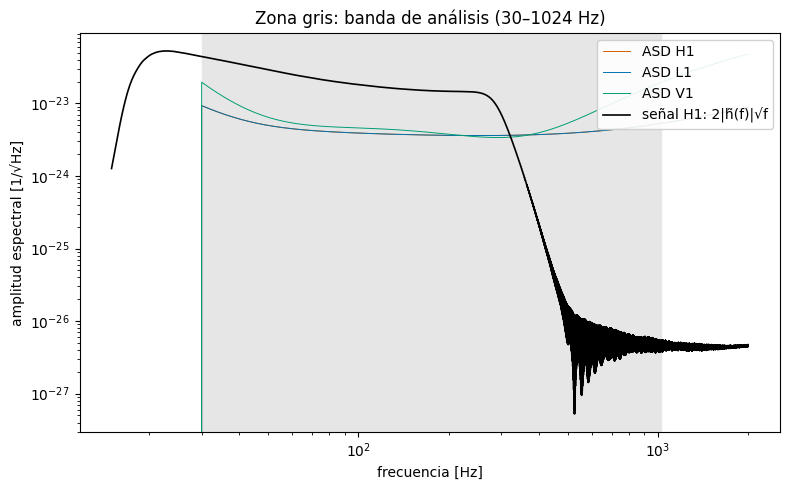

In [9]:
fig, ax = plt.subplots(figsize=(8, 5))
for j, ifo in enumerate(IFOS):
    psd = PSDS['proc'][ifo]
    f = psd.sample_frequencies.numpy()
    keep = (f >= 15) & (f <= 2000)
    ax.loglog(f[keep], np.sqrt(psd.numpy()[keep]), color=COLORS[ifo], lw=0.7, label=f'ASD {ifo}')
hf = TimeSeries(out['signal_projected'][0].astype(np.float64), delta_t=cfg.delta_t).to_frequencyseries()
fs = hf.sample_frequencies.numpy()
keep = (fs >= 15) & (fs <= 2000)
ax.loglog(fs[keep], 2 * np.abs(hf.numpy()[keep]) * np.sqrt(fs[keep]), color='k', lw=1.2, label='señal H1: 2|h̃(f)|√f')
ax.axvspan(30, 1024, color='0.9', zorder=0)
ax.set_xlabel('frecuencia [Hz]')
ax.set_ylabel('amplitud espectral [1/√Hz]')
ax.set_title('Zona gris: banda de análisis (30–1024 Hz)')
ax.legend(loc='upper right', framealpha=0.9)
plt.tight_layout()
plt.show()

Por último, el **z-score**: por detector, X = (x − media) / (desviación + 10⁻⁶). Quita la escala absoluta, que depende de la PSD de cada momento, y deja cada canal con media 0 y desviación 1. Lo comprobamos a mano desde `X_unnormalized`. La diferencia con `X` es del orden del redondeo de float32.

In [10]:
xu = out['X_unnormalized'].astype(np.float64)
manual = (xu - xu.mean(axis=1, keepdims=True)) / (xu.std(axis=1, keepdims=True) + 1e-6)
print('máx |z-score a mano − X| =', float(np.abs(manual - out['X']).max()))
print('media por detector:', out['X'].mean(axis=1).round(6), ' desviación:', out['X'].std(axis=1).round(6))

máx |z-score a mano − X| = 2.583437161973734e-07
media por detector: [-0. -0. -0.]  desviación: [1. 1. 1.]


## 6. Las cuatro salidas, lado a lado (H1)

| Salida | Qué es | Unidades |
|---|---|---|
| `signal_projected` | la señal S en el detector, sin ruido ni procesado | strain |
| `strain_noisy_raw` | señal + ruido, sin procesar | strain |
| `signal_whitened` | la señal sola, blanqueada y filtrada (sin z-score) | adimensional |
| `X` | señal + ruido, blanqueados, filtrados y con z-score | adimensional |

La línea vertical marca la coalescencia. En `strain_noisy_raw` el ruido de baja frecuencia domina por completo; tras el blanqueado, la señal reaparece como un *chirp* de pocas décimas de segundo, que en `X` está mezclado con el ruido.

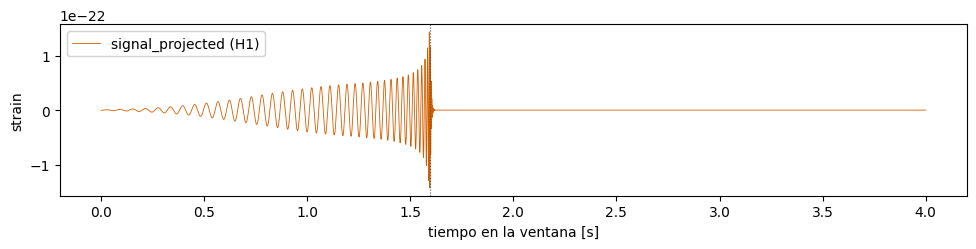

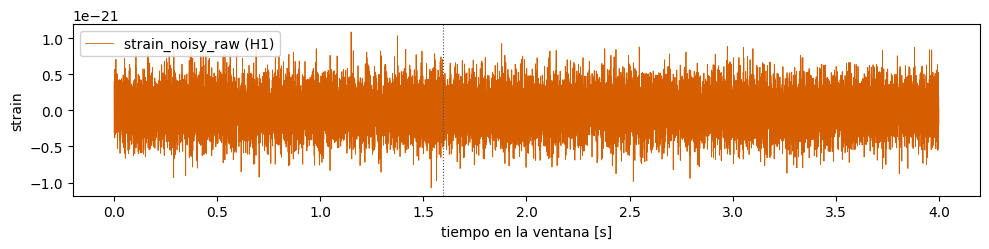

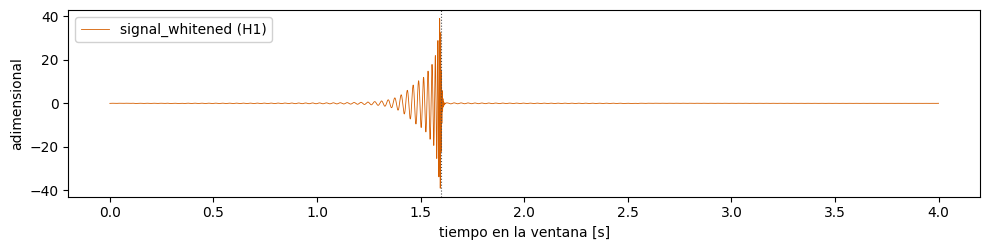

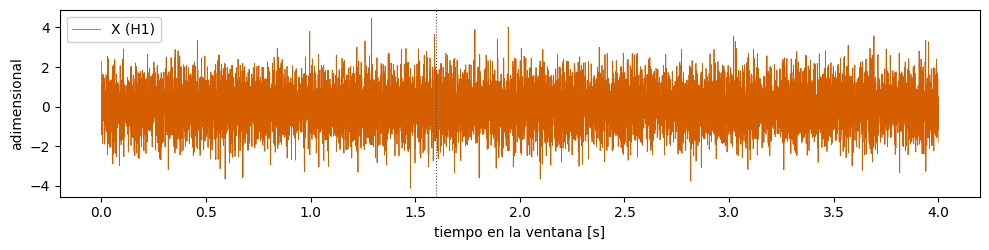

In [11]:
panels = [('signal_projected', 'strain'), ('strain_noisy_raw', 'strain'),
          ('signal_whitened', 'adimensional'), ('X', 'adimensional')]
for name, unit in panels:
    fig, ax = plt.subplots(figsize=(10, 2.6))
    ax.plot(t, out[name][0], color=COLORS['H1'], lw=0.6, label=f'{name} (H1)')
    ax.axvline(t_c, color='0.3', lw=0.8, ls=':')
    ax.set_xlabel('tiempo en la ventana [s]')
    ax.set_ylabel(unit)
    ax.legend(loc='upper left', framealpha=0.9)
    plt.tight_layout()
    plt.show()

Como el procesado es lineal, `X_unnormalized` = procesado(ruido) + `signal_whitened`. Por eso las salidas `X` y `X_noise` de la misma fila comparten exactamente el mismo ruido: ese es el punto de partida del tutorial 04.

**Siguiente:** `02_ruido_y_psd.ipynb`.